# <center>VAI Academy</center>
# <center> Introdução a Machine Learning </center>
___

# <center> Objetivos de aprendizado </center>
- Familiarizar-se com as classes de algoritmos de ML
- Familiarizar-se com alguns termos específicos da Ciência de Dados
- Familiarizar-se com as métricas mais utilizadas na construção de modelos de ML
___

## Conteúdo
1. [Introdução](#intro) <br>
2. [Definição](#def) <br>
3. [Ciclo de Projetos de Data Science](#ciclo) <br>
4. [Classes de algoritmos de ML](#classes) <br>
5. [Aprendizado Supervisionado](#supervised) <br>
6. [Aprendizado Não Supervisionado](#unsupervised) <br>

<a id="dsprecap"></a>

Parte do conteúdo dessa aula também está disponível em formato de vídeo. Os vídeos já estão inseridos no notebook e aparecem no mesmo ao rodar as células com a função ```YouTubeVideo```, como a próxima.

<a id='supervised'></a>
## 5. Aprendizado supervisionado

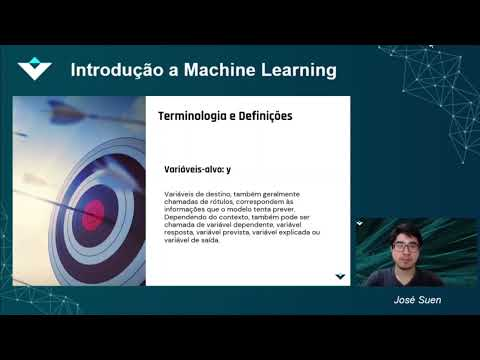

In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo('hjIGvacYMlE', width = 640, height = 360)

Como acabamos de observar, os algoritmos de aprendizado supervisionado usam um conjunto de pares de características-alvo $ (X, y) $ sobre os quais o modelo deve ser treinado (dado $ X $, preveja $ y $). Em seguida, ele tenta prever a resposta a observações novas e não vistas anteriormente.

<img src=https://christophm.github.io/interpretable-ml-book/images/learner.png width='300'/>

### 5.1 Terminologia e Definições

Antes de entrarmos nos fundamentos técnicos da aprendizagem supervisionada, é importante apresentar algumas definições e terminologia importantes.

#### 5.1.1 Dados estruturados vs. dados não estruturados

**Dados estruturados** geralmente residem em [bancos de dados relacionais](https://pt.wikipedia.org/wiki/Banco_de_dados_relacional) ou tabelas lidas por softwares como o Excel. Os campos armazenam números de telefone, códigos postais, país, número de irmãos, altura, etc, separados por um delimitador. Este formato permite uma **fácil pesquisa e recuperação de informações** e é muito mais fácil fazer previsões. **Dados não estruturados**, por outro lado, são essencialmente todo o resto. Possuem alguma estrutura interna, mas não são estruturados por meio de modelos ou padrões predefinidos. Os dados não estruturados típicos incluem arquivos de texto (e-mails, livros, artigos, ...), áudios e imagens.

#### 5.1.2 Observação $ (x_i, y_i) $

Também chamada de instância, amostra ou exemplo, uma observação se refere a uma única linha em um conjunto de dados estruturado ou a uma única imagem/música/e-mail em um conjunto de dados não estruturado. Em um gráfico de dispersão, corresponderia a um único ponto em um espaço N-dimensional, onde N é o comprimento do vetor $ x_i $.

#### 5.1.3 Características (Features) $ X $

As características correspondem ao conjunto de entradas usadas para a **previsão**. Elas descrevem a observação para que o modelo possa usá-los para fazer uma previsão. Dependendo do contexto, as características podem ter nomes diferentes: variável controlada, variável explicativa ou variável de entrada.

#### 5.1.4 Variáveis-alvo $ y $

Variáveis de destino, também geralmente chamadas de rótulos, correspondem às informações que o modelo tenta **prever**. Dependendo do contexto, também pode ser chamada de variável dependente, variável resposta, variável prevista, variável explicada ou variável de saída.

#### 5.1.5 Parâmetros e hiperparâmetros do modelo

**Parâmetros do modelo** consistem naqueles **ajustados automaticamente ao longo do processo de aprendizagem**. Eles geralmente correspondem a pesos que multiplicam cada característica (representando o quanto aquela característica explica a variável alvo). Por outro lado, **hiperparâmetros do modelo** consistem nos parâmetros cujo valor deve ser **definido antes** do processo de aprendizagem começar, pois **controla seu comportamento**. O processo de ajuste dos hiperparâmetros do modelo para obter aqueles que otimizam o desempenho do modelo é conhecido como **ajuste de hiperparâmetros**.

É importante ter em mente que cada modelo de aprendizado de máquina tem seu próprio conjunto de parâmetros e hiperparâmetros.

#### 5.1.6 Conjuntos de treinamento, validação e teste

* **Conjunto de treino**: as amostras de dados que são usadas para ajustar o modelo. Ele aprende e ajusta seus parâmetros a partir deste conjunto.
* **Conjunto de validação**: as amostras de dados usadas para fornecer uma avaliação imparcial de um modelo ajustado ao conjunto de dados de treino durante o ajuste dos hiperparâmetros do modelo.
* **Conjunto de teste**: as amostras de dados usadas para fornecer uma avaliação imparcial do modelo final ajustado no conjunto de dados de treino.

Existem diferentes abordagens para treinar e avaliar. Um método comum é o **método de _holdout_**. Ele usa os conjuntos de treino e validação para ajuste de hiperparâmetros e relatórios de desempenho, respectivamente. Basicamente, particionamos um conjunto de dados em conjuntos de treino, validação e teste. Usamos o conjunto de treino para ajustar um modelo fornecendo um conjunto de hiperparâmetros e, em seguida, usamos o conjunto de validação para avaliar o desempenho do modelo com base nos hiperparâmetros fornecidos. Repetimos essas duas etapas com conjuntos diferentes de hiperparâmetros e escolhemos o conjunto que tem o melhor desempenho na validação. Em seguida, usamos os conjuntos de treino e validação para treinar nosso modelo final e o aplicamos ao conjunto de teste para avaliar/relatar o desempenho dessa generalização. A figura a seguir ilustra o procedimento:

<img src=https://i.stack.imgur.com/pXAfX.png) width='500'/>

Outras técnicas de separação dos dados, como a validação cruzada (cross-validation), serão apresentadas ao longo do curso.

#### 5.1.7 Fronteiras de decisão

Em problemas de classificação, o que o algoritmo de aprendizagem está fazendo, do ponto de vista topológico, é na verdade ajustar os parâmetros de uma hipersuperfície (superfície em um espaço N-dimensional - por exemplo, linha em 2D e superfície em 3D). Os pontos de um lado dessa superfície são classificados como pertencentes a uma classe e todos os do outro lado como pertencentes à outra classe. Essa hipersuperfície é então chamada de fronteira de decisão.

Se o limite de decisão for um hiperplano, o problema de classificação será linear e as classes serão linearmente separáveis. Com isso, percebe-se que **dependendo dos dados**, é impossível construir um bom classificador, independentemente do modelo que você usar.

<img src=https://scipython.com/static/media/uploads/blog/logistic_regression/decision-boundary.png width='500'/>

Para ter uma boa previsão, a qualidade dos dados de treino é muito mais importante do que o próprio modelo. Tomemos por exemplo a seguinte situação: em vez de ter que ajustar uma fronteira de decisão não linear mais complexa aos nossos dados, por meio da manipulação dos dados (também chamado de _feature engineering_, por exemplo, representando nossas características, features, em coordenadas polares), obtemos um problema separável linearmente no qual podemos usar modelos mais simples. **Bons dados e modelos simples são nosso objetivo final**!

### 5.2 Classificação e Regressão

O aprendizado de máquina gera muita confusão porque é aplicável em uma ampla variedade de casos e há muitos algoritmos diferentes para escolher. Além disso, cada algoritmo é adequado para responder determinadas perguntas sobre um problema.

Portanto, para entender melhor os algoritmos de aprendizado de máquina, é útil separá-los em grupos baseados em como eles funcionam. Já falamos sobre aprendizado de máquina supervisionado e não supervisionado, mas também existem diferenças entre esses algoritmos com base nos resultados que eles nos fornecem. Dessa forma, temos dois tipos populares de problemas de aprendizado de máquina: _classificação_ e _regressão_.

Na **classificação**, o programa de computador aprende com os dados que são fornecidos a ele e então usa esse conhecimento adquirido para classificar novas observações em uma classe a partir de uma lista predefinida de classes finitas possíveis para aquela observação.

A classificação é geralmente separada em **classificação binária**, caso particular de classificação entre exatamente duas classes, e **classificação multiclasse**, que é a classificação entre mais de duas classes.

> **Saiba mais:** Na classificação binária, costumamos falar de uma classe sendo a *classe positiva* e a outra classe sendo a *classe negativa*. Aqui, positivo não representa ter benefício ou valor, mas sim o que o objeto
do estudo é. Qual das duas classes é chamada de positiva é frequentemente uma questão subjetiva e específica do domínio do problema <br>

Para problemas de **regressão**, o computador também aprende os dados que lhe são fornecidos, mas seu objetivo é prever um número contínuo e não uma classe. Portanto, a **principal diferença entre essas duas abordagens é o objetivo/as perguntas que se deseja responder!**

<img src=https://www.researchgate.net/profile/Yves_Matanga2/publication/326175998/figure/fig9/AS:644582983352328@1530691967314/Classification-vs-Regression.png alt="drawing" width="400"/>
<center> <a href="https://www.researchgate.net/profile/Yves_Matanga2/publication/326175998" style="text-align:center">Fonte da imagem</a> </center>

Uma maneira fácil de saber que tipo de problema você está enfrentando é questionar se há algum tipo de continuidade no resultado que queremos alcançar: uma pessoa ganhar 40.000 ou 40.001 dólares por ano não faz uma diferença gritante no nosso problema, mesmo que sejam quantias diferentes de dinheiro, e, portanto, poderiam ser classificadas em diferentes classes. Neste caso, prever quanto uma pessoa ganha por ano é um problema de regressão.

Em contrapartida, para a tarefa de reconhecer a linguagem de um site, não há um problema de intensidade. Um site está em um idioma ou em outro. Não há continuidade entre os idiomas, e é bem improvável que um site seja apresentado em um idioma que esteja entre o inglês e o japonês, por exemplo. Portanto, este é um problema de classificação.

#### 5.2.1 Exemplos de problemas

Agora que a diferença entre cada tipo de problema está mais clara, podemos ver alguns exemplos de aplicação para cada um.

Problemas comuns nos quais podemos aplicar os algoritmos de **classificação** são:

1. **Reconhecimento de fala**: classificar um som como uma voz humana e, se possível, identificar a voz. Muito útil para aplicações como a Siri, sistemas de casas automatizadas e etc.
2. **Reconhecimento de escrita a mão**: converter anotações de reuniões para formatos digitais, resolução de equações matemáticas complexas escritas a mão, detecção de fraude de assinatura e etc.
3. **Identificação biométrica**: Autenticação a partir da íris ou retina, reconhecimento facial, geometria da mão e outras formas de identificar uma pessoa para liberar acessos para áreas ou arquivos restritos.
4. **Classificação de vídeo**: quando alguém sobe algum vídeo para uma plataforma de vídeo, ele tem que ser classificado nas categorias apropriadas (música, vlog, violência, imagens sensíveis e etc) para que as pessoas encontrem os vídeos e sejam informados do seu conteúdo.
5. **Classificação de imagem**: como já citado, o reconhecimento da mesma pessoa em diferentes fotos e a identificação de objetos são exemplos aqui.
6. **Medical image diagnosis**: Diagnósticos de câncer através de imagens de ressonâncias magnéticas de tumores em diversas partes do corpo.
7. **Análise de texto**: classificação de documentos em categorias, tornando mais fácil de guardá-los e ordená-los; análise de sentimento para detecção do humor em posts de rede social e etc.

Por outro lado, algoritmos de **regressão** podem ser útil para a previsão de diversas quantidades numéricas:

1. Quantidade de vendas de um item.
2. Preço de venda de uma casa.
3. Demanda de dinheiro nos caixas eletrônicos.
4. Momento de quebra de uma máquina.
5. Número de clientes que vão ver um anúncio e clicar para ver um produto.

A utilização da regressão nesses casos podem ser tanto para a utilização do número previsto em si, como também para o apoio à decisão, criação de gatilhos para as operações, ou entendimento de como cada um dos fatores afetam o número previsto. Por exemplo, podemos tentar entender como a temperatura do forno afeta o tempo de validade dos produtos de uma fábrica, ou como o número de reclamações é afetado pelo tempo de espera em um call center.

#### 5.2.2 Exemplo práticos

Para exemplificar os modelo supervisionado, utilizaremos um modelo simples de regressão com dados criados artificialmente abaixo.

##### 1 - Regressão
Para exemplificar um modelo de regressão, geraremos dados aleatórios baseados na fórmula abaixo.

$ y = b_{0} + b_{1} * X + b_{res} * R $

Você poderá variar os valores de $b_{0}$, $b_{1}$ e $b_{res}$, além da média e desvio de $X$, e verificar os dados gerados no gráfico a seguir. O termo R é randômico e trará mais a aleatoriedade aos nossos dados

In [2]:
mean_x = 20       # media de x
sd_x = 10         # desvio padrao de x
b0 = 50
b1 = 4
b_res = 20

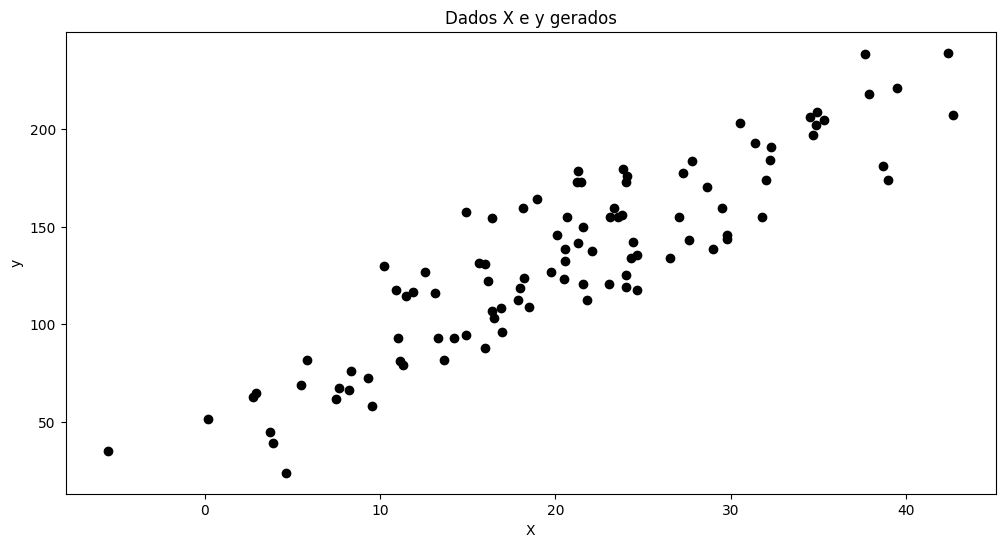

In [6]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# Gerando dados aleatórios
np.random.seed(0)
X = sd_x * np.random.randn(100) + mean_x
res = b_res * np.random.randn(100)
y = b0 + b1 * X + res

df = pd.DataFrame({'X': X, 'y': y})

plt.figure(figsize=(12, 6))
plt.scatter(X, y,  color='black')
plt.title('Dados X e y gerados')
plt.xlabel('X')
plt.ylabel('y')

plt.show()

Agora, faremos um modelo de regressão linear sobre esse dado e mostraremos a linha de regressão no gráfico abaixo. O que você precisa entender agora é que quanto mais próximo à linha gerada estiver dos pontos de dados, melhor é o modelo.

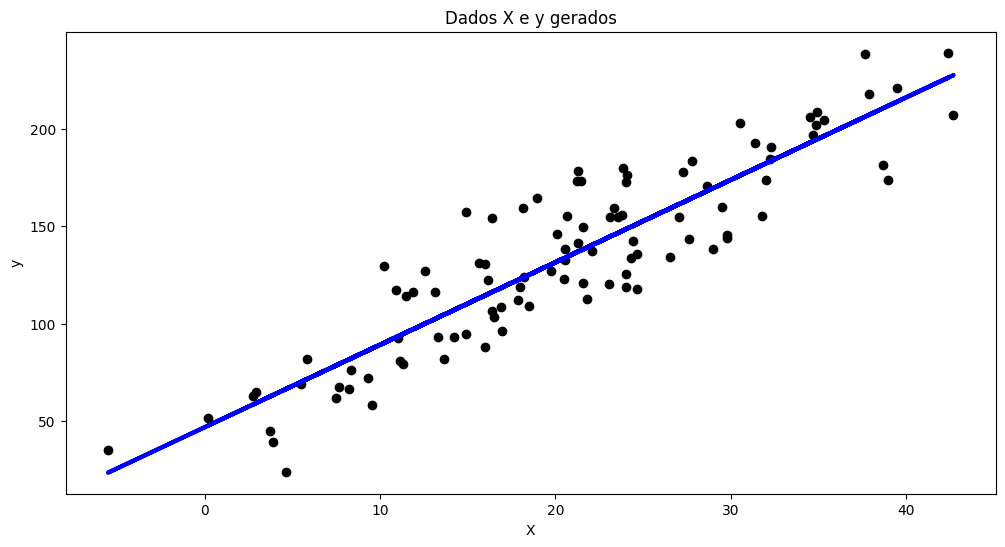

In [7]:
from sklearn import datasets, linear_model

regr = linear_model.LinearRegression()
regr.fit(df['X'].values.reshape(-1, 1), df['y'])
y_pred = regr.predict(df['X'].values.reshape(-1, 1))

plt.figure(figsize=(12, 6))
plt.scatter(X, y,  color='black')
plt.plot(X, y_pred, color='blue', linewidth=3)
plt.title('Dados X e y gerados')
plt.xlabel('X')
plt.ylabel('y')

plt.show()

Podemos prever o valor de y para qualquer lista de valores de X usando o nosso modelo de regressão linear agora. Tente alterar a lista abaixo e verificar os valores previstos para tais valores X. Verifique se os valores previstos de y se "encaixam" nos dados aleatórios que usamos no treino pelo gráfico.

In [8]:
X_pred = [0, 5, 10, 15, 20, 25, 30, 35, 40]

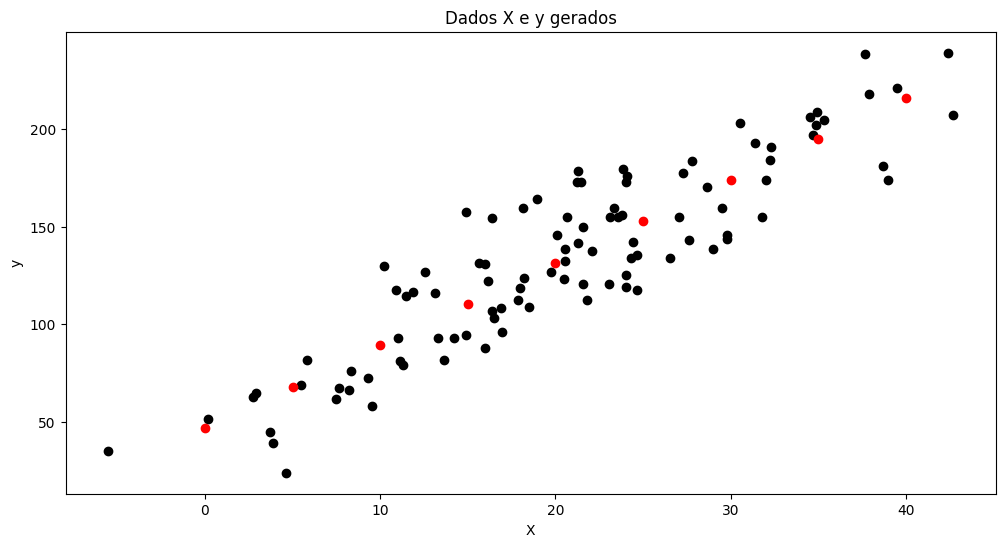

In [9]:
y_pred_new = regr.predict(np.array(X_pred).reshape(-1, 1))

plt.figure(figsize=(12, 6))
plt.scatter(X, y,  color='black')
plt.scatter(X_pred, y_pred_new,  color='red')
plt.title('Dados X e y gerados')
plt.xlabel('X')
plt.ylabel('y')

plt.show()

#### 5.2.3 Principais métodos

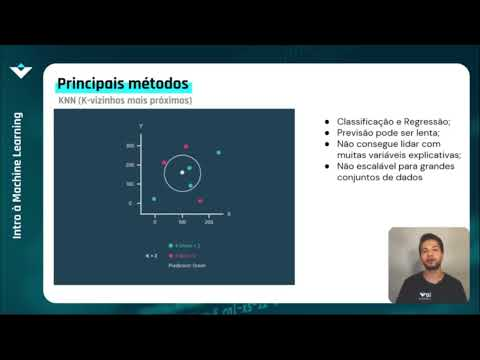

In [10]:
from IPython.display import YouTubeVideo
YouTubeVideo('wacRwPROeJU', width = 640, height = 360)

A escolha do algoritmo de aprendizado de máquina depende de vários fatores, como:

- Quantidade, qualidade e diversidade dos dados
- A precisão do modelo.
- A interpretabilidade do modelo.
- A complexidade do modelo.
- A escalabilidade do modelo.
- Quanto tempo leva para construir, treinar e testar o modelo?
- Quanto tempo leva para fazer previsões usando o modelo?
- O modelo atende ao objetivo do negócio?

Portanto, escolher o algoritmo certo é uma combinação de necessidade do negócio, especificidade, experimentação e tempo disponível. Mesmo os cientistas de dados mais experientes não podem dizer qual algoritmo terá o melhor desempenho antes de experimentá-los. Portanto, a escolha correta do algoritmo é incerta, a menos que testemos nossos algoritmos diretamente com o bom e velho método de tentativa e erro.

Porém, existem alguns prós e contras em cada algoritmo de ML que podemos usar como guia. Embora um algoritmo nem sempre seja melhor que outro, existem algumas propriedades de cada algoritmo que podemos usar como um auxílio para selecionar rapidamente aquele que melhor se adapta às nossas necessidades.

Nesta seção, vamos nos concentrar nos métodos principais, fornecendo algumas explicações simples sobre o que eles fazem e explorando seus pontos fortes e fracos. Isso te ajudará a encontrar o mais adequado para seus desafios específicos.

**k-vizinhos mais próximos (k-Nearest Neighbors/k-NN)**

O algoritmo k-NN é o algoritmo de aprendizado de máquina mais simples. É tão simples que não armazena realmente um modelo, mas simplesmente consiste em armazenar o conjunto de dados de treino. Para prever um novo ponto, ele olha para os *k* pontos mais próximos desse novo ponto (esses são seus vizinhos mais próximos) e pode ser usado para problemas de classificação e regressão!

Agora, se estamos lidando com um problema de **classificação**, este algoritmo calcula uma votação por maioria simples de todos os k vizinhos mais próximos. Isso significa que para cada ponto, ele conta quantos vizinhos pertencem à classe 0, quantos vizinhos pertencem à classe 1 e assim por diante, até contar os votos para todos os k vizinhos. Em seguida, **atribui a classe que é a classe majoritária entre os k pontos de votação mais próximos ao novo ponto**. Dê uma olhada nas fotos abaixo para uma ilustração com K = 1 e K = 3 em um problema de classificação binária (classe 0 - círculo azul ou classe 1 - triângulo vermelho):

<img src=https://i.imgur.com/ze80Lz8.png alt="drawing" width="900"/>
<center> Adaptado de: <a href="https://www.amazon.com.br/Introduction-Machine-Learning-Andreas-Mueller/dp/1449369413" style="text-align:center">Introduction to Machine Learning with Python</a> </center>

Aqui, as estrelinhas representam novos pontos no conjunto de dados que queremos classificar. Observe que a mudança de k de 1 para 3 altera a previsão de classificação do novo ponto superior esquerdo, uma vez que a votação leva em consideração os 3 vizinhos mais próximos e não apenas o mais próximo (quando k = 1).

O processo é quase análogo para um problema de **regressão**, mas em vez de votar para selecionar a classe majoritária, pegamos o valor médio dos *k* vizinhos mais próximos e o atribuímos ao novo ponto. Veja um problema semelhante ao mostrado no exemplo anterior, mas agora para um problema de regressão:

<img src=https://i.imgur.com/v0KbH6L.png alt="drawing" width="1000"/>
<center> Adaptado de: <a href="https://www.amazon.com.br/Introduction-Machine-Learning-Andreas-Mueller/dp/1449369413" style="text-align:center">Introduction to Machine Learning with Python</a> </center>

Observe que, diferentemente do problema de classificação, não estamos preocupados com a classe do novo ponto, mas com seu valor contínuo.

As **vantagens** do k-NN são que o método é muito fácil de entender e o aprendizado é rápido, uma vez que não há treinamento explícito, o que o torna um método ideal para tentar antes de considerar técnicas mais avançadas.

A **desvantagem** do k-NN é que a previsão pode ser lenta, pois o método tem que comparar cada novo ponto com todos os outros pontos existentes para calcular a distância e só então fazer a própria previsão. Além disso, esse método não funciona bem em conjuntos de dados com muitas caracaterísticas ou onde a maioria das características está concentrada em apenas uma classe (também chamado de conjuntos de dados esparsos).

Portanto, embora o algoritmo k-vizinhos mais próximos seja fácil de entender, ele não é usado com frequência, na prática, devido à lentidão da previsão e à sua incapacidade de lidar com muitas variáveis explicativas.

**Regressão linear**

A regressão linear é o método linear mais simples e clássico de regressão e é um método estatístico que permite resumir e estudar as relações entre duas variáveis contínuas (quantitativas), sendo, portanto, aplicado a **problemas de regressão**.

Se tivermos apenas uma variável explicativa e uma variável alvo, a regressão linear assume a forma de **Regressão Linear Simples**, que modela a relação entre a única variável independente da entrada (variável explicativa) e a única variável dependente alvo usando um modelo linear, ou seja, uma linha. Há um caso mais geral, **Regressão Linear Múltipla**, onde um modelo é criado para a relação entre várias variáveis de entrada independentes (variáveis explicativas) e a variável dependente alvo. Embora tenhamos várias variáveis explicativas, o modelo permanece linear no sentido de que a saída é uma combinação linear das variáveis de entrada.

<img src=https://forum.huawei.com/enterprise/en/data/attachment/forum/202103/24/105512n3yu23o5xy563bhn.png?35.png alt="drawing" width="400" height="400"/>


<img src=https://forum.huawei.com/enterprise/en/data/attachment/forum/202103/24/105612h6yv5749k1vve916.png?36.png alt="drawing" width="400" height="400"/>

<center> Adaptado de: <a href="https://forum.huawei.com/enterprise/en/machine-learning-algorithms-linear-regression/thread/710183-895?page=2" style="text-align:center">Huawei</a> </center>




Como a regressão linear é bastante simples de entender, este é um bom algoritmo inicial e pode ser muito valioso para decisões de negócios: **sempre que for solicitado a prever algum valor futuro de um processo que está em execução, você pode usar um algoritmo de regressão!**. Outra vantagem desse método é que é muito rápido treinar e prever valores, o que o torna escalável para conjuntos de dados muito grandes e funciona bem com dados esparsos (nos quais o número de características é grande em comparação com o número de amostras do conjunto de dados de treino).

Quanto às **desvantagens**, este modelo não é bom como os outros quando se trata de dados altamente complexos (ou seja, dados não lineares) e não fica tão claro como ele obtém a importância de cada característica. Além disso, como este modelo funciona bem com um grande número de características, há uma chance maior de [*overfitting*](https://en.wikipedia.org/wiki/Overfitting). Não se preocupe com esse conceito complexo agora, mas pense nisso como se o modelo só fosse bom para os dados que você já conhece o valor/rótulo real e não pode prever novos valores/classes muito bem.

**Regressão Logística**

A Regressão Logística é outro tipo de método linear amplamente utilizado e também um dos mais importantes, mas, apesar do nome, realiza uma **classificação (binária)**. Uma boa analogia para ajudar a entendê-la é pensar na regressão logística como um caso especial de regressão linear quando a variável de destino é categórica.

<img src=https://cdn-images-1.medium.com/max/1600/0*vRhSdZ_k4wrP6Bl8.jpg alt="drawing" width="500"/>


<center> Fonte: <a href="https://ai.plainenglish.io/a-comparison-of-sklearn-and-statsmodels-logistic-regression-function-4340e9fd29dd" style="text-align:center">Logistic Regression</a> </center>

A regressão logística é geralmente usada quando a variável alvo é Binária ou Dicotômica. Isso significa que a variável dependente pode assumir apenas dois valores possíveis, como “Sim ou Não”, “Padrão ou Não Padrão”, “Vivo ou Morto”, “Respondente ou Não Respondente”, etc. As características podem ser variáveis categóricas ou numéricas.

Como também é um algoritmo linear, as **vantagens** e **desvantagens** da regressão logística são muito semelhantes às da regressão linear. É importante notar, porém, que a regressão logística é mais adequada para problemas de classificação do que a regressão linear, uma vez que seus valores variam estritamente de 0 a 1, enquanto a regressão linear é ilimitada.

**Árvores de decisão**

Árvores de decisão, como o nome sugere, é um algoritmo que constrói modelos na forma de uma estrutura de árvore que toma uma decisão, tanto para tarefas de **classificação** quanto de **regressão**. Essencialmente, este algoritmo aprende uma hierarquia de perguntas se/senão que levam a uma decisão, de forma a fazer o mínimo de perguntas possível! Em outras palavras, aprender uma árvore de decisão significa aprender a sequência de perguntas se/senão que nos leva mais rápido à resposta verdadeira.

Imagine que você queira decidir se joga ao ar livre com seus amigos ou não. Que perguntas você faria para decidir isso? A árvore de decisão a seguir fornece uma sequência de perguntas que você pode responder para decidir isso!

<img src=https://i.imgur.com/xd7rdW8.png alt="drawing" width="600"/>

Podemos ver que cada nó representa um atributo ou característica e a ramificação de cada nó representa o resultado desse nó. Finalmente, é nas folhas da árvore que a decisão final é tomada. Portanto, para o exemplo acima, se o tempo estiver ensolarado e a umidade estiver abaixo de 75%, então eu decidirei brincar ao ar livre. Por outro lado, se o tempo estiver chuvoso e o vento estiver acima de 20 mph, a árvore diz que é melhor ficarmos em casa.

Árvores de decisão aceitam variáveis explicativas categóricas e contínuas/numéricas. Para variáveis categóricas, normalmente as respostas das perguntas são Verdadeiro/Falso ou Sim/Não e se estivermos lidando com variáveis contínuas, as perguntas estão no formato "A variável *i* é maior/menor que o valor _a_?".


O uso e a análise de **árvores de regressão** são muito semelhantes aos de **árvores de classificação**. Enquanto em uma tarefa de classificação a saída é categórica, em árvores de regressão o alvo é um valor contínuo/numérico.

As árvores de decisão têm duas vantagens sobre muitos dos algoritmos que discutimos até agora: o modelo resultante pode ser facilmente visualizado e compreendido por não especialistas (pelo menos para árvores menores) e os algoritmos são completamente invariáveis no que diz respeito ao tamanho do conjunto de dados. Como cada variável explicativa é processada separadamente e as possíveis divisões dos dados não dependem da escalabilidade, nenhum pré-processamento como normalização ou padronização de variáveis é necessário para algoritmos de árvore de decisão. Em particular, as árvores de decisão funcionam bem quando você tem variáveis que estão em escalas completamente diferentes ou uma mistura de variáveis binárias e contínuas. Além disso, como consequência da vantagem anterior, é muito fácil adicionar novas variáveis ao modelo.

A principal desvantagem das árvores de decisão é que elas tendem a se ajustar demais (*overfit*) e fornecer baixo desempenho na generalização. Outro cuidado a ser tomado ao lidar com modelos de árvore é que eles podem criar árvores tendenciosas se algumas classes forem dominantes. É por isso que você deve ter cuidado com o ajuste dos parâmetros!

Outra desvantagem de todos os modelos baseados em árvore **quando usados para tarefas de regressão** é que eles não podem extrapolar, ou seja, fazer previsões fora do intervalo dos dados de treinamento (ou seja, um modelo de regressão baseado em árvore nunca preveria um preço de casa mais alto do que a casa mais cara em nosso conjunto de dados de treinamento).

Lembre-se que os exemplos citados acima não são exaustivos em explicar todos os modelos existentes. Existem diversas ferramentas de *Machine Learning* além das apresentadas, convidamos você a se aprofundar e tentar conhecê-las.

#### 5.2.4 Métricas

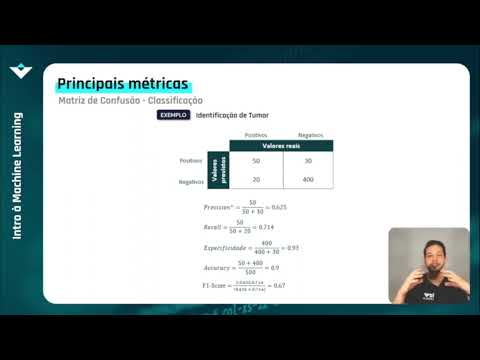

In [11]:
from IPython.display import YouTubeVideo
YouTubeVideo('GGVyu_9_V40', width = 640, height = 360)

Agora que já aprendemos sobre os principais algoritmos usados em problemas de ML supervisionados, vamos aprender algumas das principais métricas de avaliação usadas para comparar seu desempenho e selecionar o melhor modelo a ser utilizado!

Assim como existem diferentes tipos de algoritmos supervisionados, também existem diferentes métricas para cada tipo de problema que estamos enfrentando:

<img src=https://cdn-images-1.medium.com/max/1600/1*1WPbfzztdv50V22TpA6njw.png alt="drawing" width="600"/>
<center> Fonte: <a href="https://medium.com/usf-msds/choosing-the-right-metric-for-evaluating-machine-learning-models-part-2-86d5649a5428" style="text-align:center">Evaluating machine learning models</a> </center>


**Classificação**

Antes de iniciarmos a definição de algumas métricas, vamos primeiro entender algumas terminologias básicas usadas em problemas de classificação:

- **Verdadeiro positivo (TP)**: Um resultado de teste verdadeiro positivo é aquele que detecta a condição quando a condição está presente
- **Verdadeiro negativo (TN)**: Um resultado de teste verdadeiro negativo é aquele que não detecta a condição quando a condição está ausente
- **Falso positivo (FP)**: Um resultado de teste falso positivo é aquele que detecta a condição quando a condição está ausente
- **Falso negativo (FN)**: Um resultado de teste falso negativo é aquele que não detecta a condição quando a condição está presente

- **Matriz de confusão**:
<img src=https://cdn-images-1.medium.com/max/1600/1*7SgzmX05T81Ojaor9s5HWQ.png alt="drawing" width="300"/>
<center> Fonte: <a href="https://medium.com/usf-msds/choosing-the-right-metric-for-evaluating-machine-learning-models-part-2-86d5649a5428" style="text-align:center">Evaluating machine learning models</a> </center>

- **Recall ou Sensibilidade ou TPR (True Positive Rate)**: mede a capacidade de um teste de detectar a condição quando a condição está presente - TP / (TP + FN)
- **Especificidade ou TNR (True Negative Rate)**: mede a capacidade de um teste de excluir corretamente a condição (não detectar a condição) quando a condição está ausente - TN / (TN + FP)
- **Valor preditivo positivo ou precisão**: Número de itens corretamente identificados como positivos do total de itens previstos como positivos - TP / (TP + FP)
- **Valor preditivo negativo**: é a proporção de negativos que correspondem à ausência da condição - TN / (TN + FN)
- **Taxa de Falso Positivo (FPR) ou erro Tipo I**: Número de itens identificados incorretamente como positivos do total de negativos verdadeiros - FP / (FP + TN)
- **Taxa de Falso Negativo (FNR) ou Erro Tipo II**: Número de itens identificados incorretamente como negativos do total de positivos verdadeiros - FN / (FN + TP)
- **F1-score**: É uma média harmônica de precisão e recall dada por - 2xPrecisionxRecall / (Precisão + Recall)
- **Accuracy**: Porcentagem do total de itens classificados corretamente - (TP + TN) / (TP + TN + FP + FN)

**Área sob a curva ROC (AUC - ROC)**

O AUC é uma das métricas mais populares usadas na indústria e é calculada a partir da área sob a curva ROC (Receiver Operating Characteristic), que é o gráfico de *sensibilidade* e _FPR(1-especificidade)_.

<img src=https://deparkes.co.uk/wp-content/uploads/2018/02/roc_curve_1-660x684.png alt="drawing" width="300"/>
<center> Fonte: <a href="https://deparkes.co.uk/2018/02/16/the-roc-curve/" style="text-align:center">The ROC Curve</a> </center>

Portanto, AUC é a razão entre a área sob a curva ROC e a área total.


- O valor do ROC - AUC pode variar de 0 a 1, com o AUC de um modelo de classificação aleatório com dados balanceados sendo 0.5.
    - 0.90 - 1 = excelente (cuidado com overfitting)
    - 0.80 - 0.90 = bom
    - 0.70 - 0.80 = justo
    - 0.60 - 0.70 = ruim
    - 0.50 - 0.60 = errado






**Regressão**

Existem muitas métricas que podem ser usadas para analisar modelos de regressão, mas as mais populares são as métricas ```RMSE```, ```MAE``` e ```MAPE```. A seguir, descreveremos em poucas palavras essas métricas, mas não se preocupe tanto com sua compreensão no momento porque elas serão retomadas com mais detalhes no decorrer do curso.

**RMSE (erro quadrático médio)**

Ele representa o desvio padrão das diferenças entre os valores previstos e os valores observados (chamados de resíduos). Matematicamente, é calculado usando esta fórmula:

$$ RMSE = \sqrt{\frac{1}{n}\Sigma_{i=1}^{n}{\Big({y_i -\hat{y}_i}\Big)^2}}$$

**MAE (erro médio absoluto)**

MAE é a média da diferença absoluta entre os valores previstos e os valores observados. O MAE é uma métrica linear, o que significa que todas as diferenças individuais são ponderadas igualmente na média. Por exemplo, a diferença entre 10 e 0 será o dobro da diferença entre 5 e 0. Matematicamente, é calculado usando esta fórmula:

$$ MAE = \frac{1}{n}\sum_{i=1}^{n} |{y_i -\hat{y}_i}| $$

**MAPE (erro médio absoluto percentual)**
MAPE é o valor médio relativo entre os valores previstos e os observados, podemos enxergá-lo como uma visão em porcentagem da métrica MAE. A métrica MAPE é comumente utilizada por ser mais fácil de se interpretar, por exemplo se o o valor do MAPE for $14\%$ isso significa que o a diferença média entre o valor previsto e o valor real está em $14\%$.


$$ MAPE = \frac{1}{n}\sum_{i=1}^{n} \frac{|{y_i -\hat{y}_i}|}{|y_i|}100 $$

**R ao quadrado (R²) e R ao quadrado ajustado**

Essas métricas, da mesma forma que o erro ```MAPE```, são amplamente utilizadas de forma errada e incompreendidas: não são uma boa medida da capacidade preditiva de um modelo. Mesmo assim, eles têm seu valor para fins explicativos e explicam quão bem as variáveis explicativas selecionadas explicam a variabilidade da sua variável resposta.

Assim como o R², o R² ajustado mostra quão bem os termos se ajustam a uma curva ou linha, mas com um termo adicional que considera o ganho marginal de adicionar uma nova variável explicativa ao modelo. Isso é muito importante, porque apenas variáveis realmente úteis irão aumentar o R² ajustado, enquanto o R² sozinho não leva isso em consideração!

Então, no final das contas, qual métrica é melhor, R² ajustado ou RMSE? A resposta é que depende! O RMSE tem um escopo limitado para comparar os valores previstos com os valores reais, enquanto o R² ajustado pode ser usado para outras análises. Além disso, o valor absoluto de RMSE não diz realmente o quão ruim é um modelo. Portanto, é difícil analisar o RMSE sozinho, ao passo que com o R² ajustado, sabemos que quanto mais próximo de 1, melhor pode ser o modelo!

### 5.3 Underfitting e Overfitting

Vamos treinar nossa imaginação novamente!

Suponha que você tenha dois filhos pequenos, João e Daniel. Ambos terão um teste de matemática amanhã que cobrirá as operações básicas, como adição, subtração, multiplicação e divisão. Acontece que nenhum deles realmente estudou para o teste porque jogaram videogame durante a semana inteira. Portanto, cada um usa uma estratégia diferente antes do teste:
- João decide estudar e realmente aprender sobre adição, mas deixa a subtração, multiplicação e divisão de lado.
- Daniel, com a boa memória que ele tem, resolve memorizar todos os exercícios de seu livro didático.

No momento do exame, João resolve todos os problemas de adição, mas erra todos os outros. Por outro lado, Daniel acerta a resposta para todos os problemas que estavam em seu livro, mas também erra o resto.

Isso, no aprendizado de máquina, é chamado de underfitting e overfitting. <br>
Underfitting é quando nosso modelo não aprende a relação entre os valores independentes e dependentes. Overfitting é quando ele "*aprende*" tão bem que realmente memoriza as observações passadas a ele, em vez de generalizar o aprendizado para o mundo real.

Outro exemplo pode ser visto na imagem abaixo. <br>
**O gráfico à esquerda** mostra uma tentativa de ajustar os dados com uma linha. Podemos ver claramente que a linha não se ajustou bem aos dados. Isso é o underfitting. <br>
**O gráfico à direita** mostra uma tentativa de ajustar uma função polinomial de grau mais elevado aos dados. É possível ver que a função mapeia os dados quase perfeitamente, mas isso pode significar que novos dados não serão bem generalizados com esta função. Isso é overfitting. <br>
**O gráfico no meio** mostra um equilíbrio entre aprender muito pouco e aprender em excesso, sendo, ao mesmo tempo bom para os dados já apresentados a ele e para os novos dados.

![over_under_fitting](https://cdn-images-1.medium.com/max/800/1*_7OPgojau8hkiPUiHoGK_w.png)

# Declaração de Inexistência de Plágio:

1. Eu sei que plágio é utilizar o trabalho de outra pessoa e apresentar como meu.
2. Eu sei que plágio é errado e declaro que este notebook foi feito por mim.
3. Tenho consciência de que a utilização do trabalho de terceiros é antiético e está sujeito a medidas administrativas.
4. Declaro também que não compartilhei e não compartilharei meu trabalho com o intuito de que seja copiado e submetido por outra pessoa.

In [12]:
# LEMBRE-SE DE SALVAR O NOTEBOOK ANTES DE EXECUTAR ESSA CÉLULA
token = '' # seu token aqui

# Não altere o código abaixo
import requests as req
%matplotlib
exec(req.get('https://api.vai.academy/submissioncode2').text)
%matplotlib inline

Using matplotlib backend: <object object at 0x7ff956a9f6b0>
Importante: lembre-se de salvar o notebook antes de rodar esta célula!
Executando o seu notebook para a submissão. Isso pode demorar alguns instantes...
>> Verificando exercicios para correção... 
>> Submetendo exercício 1... "Score: 1/1"

Tentativa de submissao #1 / 30
Aluno: Larissa Coelho Ramos
Score: 1 / 1
Parabéns!! Você atingiu os critérios para passar neste notebook.

Pontuação por exercício
Exercicio  Pontuacao Maxima  Pontuacao Obtida
        1                 1                 1



# Fim da Aula!